# micrograd

Following Andrej Karpathy's lecture [The spelled-out intro to neural networks and backpropagation: building micrograd](https://www.youtube.com/watch?v=VMj-3S1tku0&list=PLXYLzZ3XzIbi4lL43O6fIU_ojuZwBO6vi).

In [76]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [77]:
def f(x):
    return 3*x**2 - 4*x + 5

In [78]:
f(3.0)

20.0

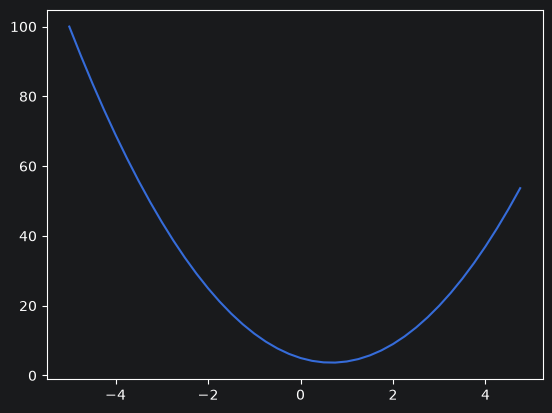

In [79]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
plt.plot(xs, ys)

In [80]:
h = 0.0001
a=2
b=-3
c=10
d1 = a*b+c
a += h
d2 = a*b+c
print((d2-d1)/h)

-3.000000000010772


In [81]:
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, val):
        return Value(self.data + val.data, (self, val), '+')

    def __sub__(self, val,):
        return Value(self.data - val.data, (self, val), '-')

    def __mul__(self, val):
        return Value(self.data * val.data, (self, val), '*')

    def __truediv__(self, val):
        return Value(self.data / val.data, (self, val), '/')


In [82]:
from graphviz import Digraph
def trace(root):
    nodes = set()
    edges = set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name = uid, label = f"{{ {n.label} | data: {n.data:.4f} | grad: {n.grad:.4f} }}", shape = 'record')
        if n._op:
            dot.node(name = uid + n._op, label = n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot


In [83]:
h = 0.0001

a=Value(2.0, label='a')
b=Value(-3.0, label='b')
c=Value(10.0, label='c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2.0, label='f')
L = d*f; L.label = 'L'
L1 = L.data

# a=Value(2.0 + h, label='a')
# b=Value(-3.0, label='b')
# c=Value(10.0, label='c')
# e = a*b; e.label = 'e'
# d = e + c; d.label = 'd'
# f = Value(-2.0, label='f')
# L = d*f; L.label = 'L'
# L2 = L.data
# print((L2-L1)/h)

L.grad = 1.0
f.grad = 4.0
d.grad = -2.0


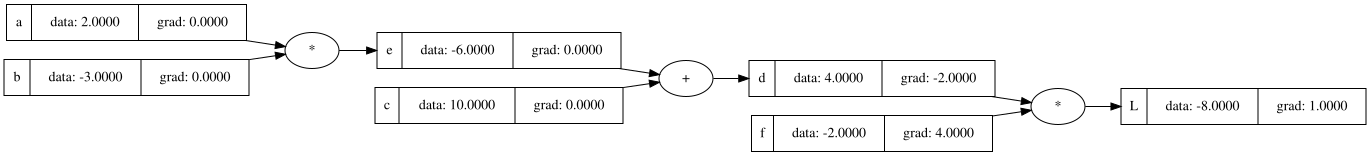

In [84]:
draw_dot(L)